### *** ML-Mini Project ***

>> *~HARSHITHA. B. T PES1UG24AM118*


# **Experiment 2: Rotation Mathematics and Validation**

## Objective
To validate the implementation of horizontal acceleration projection by checking its periodicity and its behavior at orthogonal orientations.

## Methodology
Synthetic horizontal acceleration components were generated using 1,000 samples, a sampling interval of 0.01 seconds, and a sampling frequency of 100 Hz. The projected acceleration was calculated for orientations from 0° to 179° using

a_theta(t) = a_x(t)cos(theta) + a_y(t)sin(theta)

The peak absolute acceleration was evaluated at each orientation. Two validation tests were performed: a 180° periodicity test and an orthogonal component projection test.

## Results
The maximum sampled peak projected acceleration was 1.2446 m/s² at 17°. The 180° periodicity test passed, with a maximum observed peak-response difference of approximately 2.22 × 10⁻¹⁶ m/s². The orthogonal component projection test also passed, with a maximum error of approximately 1.11 × 10⁻¹⁶ m/s² at 90° and zero error at 0°.

## Conclusion

The validation tests passed for the synthetic acceleration signals. The 180° periodicity test confirmed that the peak absolute projected acceleration was unchanged after a half-turn, and the orthogonal projection test matched the expected horizontal components within numerical tolerance.

These checks support the correctness of the projection implementation for the tested signals. They do not establish that the complete processing pipeline reproduces the reference paper's results or validate an oscillator-based RotD100 calculation.

## Limitations
The validation used synthetic sinusoidal signals and peak absolute projected acceleration. It did not validate an oscillator-based RotD100 implementation or reproduce the research paper's machine-learning results.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)

OUTPUT_DIR = Path("/content/experiment_02_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Output directory:", OUTPUT_DIR)
print("Experiment 2 initialized successfully.")

NumPy version: 2.1.3
Pandas version: 2.2.3
Output directory: /content/experiment_02_outputs
Experiment 2 initialized successfully.


In [ ]:
dt = 0.01
duration = 10.0
frequency = 1.0

time = np.arange(0, duration, dt)

ax = 1.2 * np.sin(2 * np.pi * frequency * time)
ay = 0.6 * np.sin(
    2 * np.pi * frequency * time + np.pi / 3
)

print("Number of samples:", len(time))
print("Sampling interval:", dt, "seconds")
print("Sampling frequency:", 1 / dt, "Hz")
print("X-component peak:", np.max(np.abs(ax)), "m/s²")
print("Y-component peak:", np.max(np.abs(ay)), "m/s²")

Number of samples: 1000
Sampling interval: 0.01 seconds
Sampling frequency: 100.0 Hz
X-component peak: 1.2 m/s²
Y-component peak: 0.5998684100849073 m/s²


In [ ]:

def rotate_components(ax, ay, angle_degrees):
    """Project horizontal components onto an orientation in degrees."""
    theta = np.deg2rad(angle_degrees)
    return ax * np.cos(theta) + ay * np.sin(theta)


def peak_absolute_acceleration(signal):
    """Return the maximum absolute value of a signal."""
    return np.max(np.abs(signal))


angles = np.arange(0, 180)

results = []

for angle in angles:
    projected = rotate_components(ax, ay, angle)

    results.append({
        "angle_degrees": angle,
        "peak_acceleration_m_s2":
            peak_absolute_acceleration(projected)
    })

rotation_df = pd.DataFrame(results)

max_row = rotation_df.loc[
    rotation_df["peak_acceleration_m_s2"].idxmax()
]

print("Maximum-response orientation:",
      int(max_row["angle_degrees"]), "degrees")
print("Maximum peak acceleration:",
      round(max_row["peak_acceleration_m_s2"], 4), "m/s²")

rotation_df.to_csv(
    OUTPUT_DIR / "rotation_sweep_results.csv",
    index=False
)

rotation_df.head()

Maximum-response orientation: 17 degrees
Maximum peak acceleration: 1.2446 m/s²


,angle_degrees,peak_acceleration_m_s2
0,0,1.200000
1,1,1.205053
2,2,1.209739
3,3,1.214056
4,4,1.218004


In [ ]:

test_angles = [0, 17, 45, 90, 135]

periodicity_results = []

for angle in test_angles:
    signal_1 = rotate_components(ax, ay, angle)
    signal_2 = rotate_components(ax, ay, angle + 180)

    peak_1 = peak_absolute_acceleration(signal_1)
    peak_2 = peak_absolute_acceleration(signal_2)

    periodicity_results.append({
        "angle_degrees": angle,
        "angle_plus_180_degrees": angle + 180,
        "peak_at_angle": peak_1,
        "peak_at_angle_plus_180": peak_2,
        "absolute_difference": abs(peak_1 - peak_2)
    })

periodicity_df = pd.DataFrame(periodicity_results)
display(periodicity_df)

tolerance = 1e-10
periodicity_pass = (
    periodicity_df["absolute_difference"] < tolerance
).all()

print("180-degree periodicity test:",
      "PASS" if periodicity_pass else "FAIL")

periodicity_df.to_csv(
    OUTPUT_DIR / "test_180_degree_periodicity.csv",
    index=False
)

,angle_degrees,angle_plus_180_degrees,peak_at_angle,peak_at_angle_plus_180,absolute_difference
0,0,180,1.200000,1.200000,0.000000e+00
1,17,197,1.244577,1.244577,0.000000e+00
2,45,225,1.122288,1.122288,2.220446e-16
3,90,270,0.599868,0.599868,1.110223e-16
4,135,315,0.734686,0.734686,1.110223e-16


180-degree periodicity test: PASS


In [ ]:

signal_0 = rotate_components(ax, ay, 0)
signal_90 = rotate_components(ax, ay, 90)

error_0 = np.max(np.abs(signal_0 - ax))
error_90 = np.max(np.abs(signal_90 - ay))

print("Maximum error at 0 degrees:", error_0)
print("Maximum error at 90 degrees:", error_90)

orthogonal_pass = (
    np.allclose(signal_0, ax, atol=1e-10)
    and np.allclose(signal_90, ay, atol=1e-10)
)

print("Orthogonal component test:",
      "PASS" if orthogonal_pass else "FAIL")


Maximum error at 0 degrees: 0.0
Maximum error at 90 degrees: 1.1102230246251565e-16
Orthogonal component test: PASS


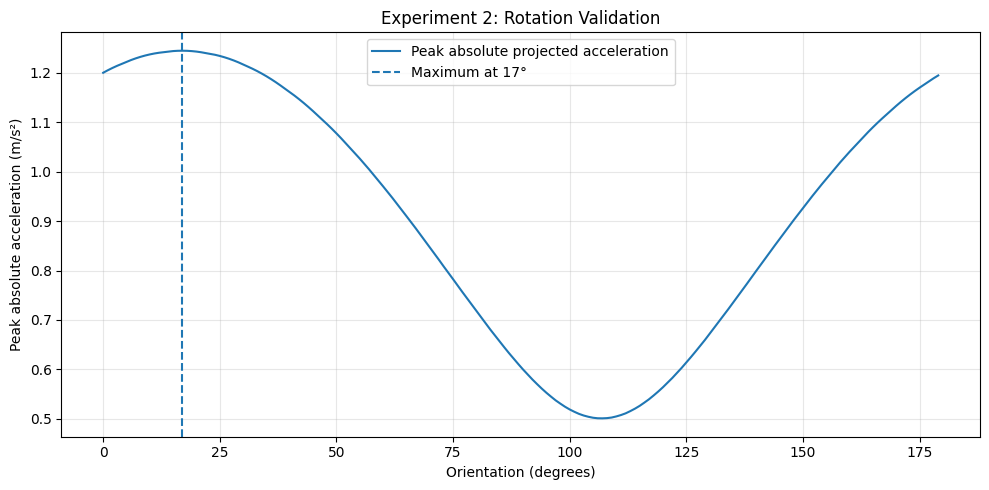

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    rotation_df["angle_degrees"],
    rotation_df["peak_acceleration_m_s2"],
    label="Peak absolute projected acceleration"
)

plt.axvline(
    max_row["angle_degrees"],
    linestyle="--",
    label=f'Maximum at {int(max_row["angle_degrees"])}°'
)

plt.xlabel("Orientation (degrees)")
plt.ylabel("Peak absolute acceleration (m/s²)")
plt.title("Experiment 2: Rotation Validation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "experiment_02_rotation_validation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
validation_summary = pd.DataFrame([
    {
        "test": "180-degree periodicity",
        "status": "PASS" if periodicity_pass else "FAIL"
    },
    {
        "test": "Orthogonal component projection",
        "status": "PASS" if orthogonal_pass else "FAIL"
    }
])

display(validation_summary)

validation_summary.to_csv(
    OUTPUT_DIR / "validation_summary.csv",
    index=False
)

print("\nSaved experiment files:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(file_path.name)

,test,status
0,180-degree periodicity,PASS
1,Orthogonal component projection,PASS



Saved experiment files:
experiment_02_rotation_validation.png
rotation_sweep_results.csv
test_180_degree_periodicity.csv
validation_summary.csv


###
The 180° periodicity test checks that the projected signal's peak absolute value is unchanged after rotating by 180°. It validates this mathematical property for your synthetic signals; it does not validate the entire earthquake-record processing pipeline.